# Графический подход к множественному тестированию в A/B-экспериментаъ

## 1. Введение и напоминание базовых концепций

### 1.1 Краткое напоминание: FWER, FDR и классические поправки

Прежде чем мы погрузимся в графический подход, давайте освежим в памяти тот фундамент, на котором всё строится. Вы уже знакомы с проблемой множественных сравнений и основными методами её решения, поэтому быстро пройдёмся по ключевым понятиям, но обязательно выделим те ограничения классических процедур, которые как раз и мотивировали создание графического подхода.

Итак, представим, что в рамках одного A/B‑эксперимента или клинического исследования мы проверяем не одну, а сразу несколько нулевых гипотез: скажем, сравниваем несколько вариантов продукта по нескольким метрикам, или анализируем несколько конечных точек эффективности и безопасности. Классический пример из области, которую мы будем рассматривать, — клиническое исследование с двумя дозами препарата, тремя иерархически упорядоченными конечными точками, итого шесть элементарных гипотез. Или, что ближе вам, A/B‑тест с контролем и тремя вариантами, где у каждого варианта есть основная метрика — выручка, и несколько guadrail метрик, например, CTR и retention. Возникает вопрос: как нам принять решение по всему этому набору гипотез, сохраняя контроль над ошибками?

Проблема хорошо известна: если каждую из $m$ независимых нулевых гипотез проверять на привычном уровне значимости $\alpha$ (например, $0.05$), то вероятность совершить хотя бы одну ошибку I рода стремительно растёт. Формально:

$$
P(\text{хотя бы одна ошибка I рода}) = 1 - (1 - \alpha)^m\;.
$$

При $m = 10$ и $\alpha = 0.05$ эта вероятность уже около $0.40$, при $m = 20$ — порядка $0.64$. Иными словами, мы почти наверняка найдём какое‑то «значимое» различие просто в силу случайности. Поэтому нам нужны специальные метрики и процедуры, которые удерживают общую вероятность ложных выводов в заданных рамках.

Центральных метрики три.

1. **Групповая вероятность ошибки I рода**, Family‑Wise Error Rate (FWER)

$$
FWER = P(V \ge 1)\;, \text{ где V — число ложноположительных результатов}
$$

Контроль FWER на уровне $\alpha$ означает, что при любом раскладе истинных и ложных гипотез вероятность допустить хотя бы одну такую ошибку не превышает $\alpha$. Этот критерий очень строг, и именно его требуют регуляторы для подтверждающих клинических испытаний, потому что главная цель — минимизировать риск пропуска на рынок неэффективного или небезопасного препарата.

2. **Доля ложных отклонений**, False Discovery Rate (FDR)

$$
FDR = \mathbb{E}\!\left[\frac{V}{\max(R,1)}\right]\;, \text{ где $R$ — общее число отвергнутых гипотез}
$$

Фактически FDR показывает, какую долю среди всех наших «находок» в среднем составляют ложные. Контроль на уровне, скажем, $0.05$ допускает, что в среднем 5% объявленных значимыми результатов будут ошибочными. Это более мягкий критерий, чем FWER, и он особенно популярен в задачах с тысячами гипотез, например, в геномике или нейровизуализации. В контексте A/B‑тестов он тоже может применяться на разведочных стадиях.

3. **Обобщённая FWER**, $k$‑FWER:

$$
k\text{-}FWER = P(V \ge k)\;.
$$

Она контролирует вероятность совершить $k$ или более ложных отклонений. При $k=1$ это обычный FWER. Увеличивая $k$, мы ослабляем контроль, но можем повысить мощность — это полезно, когда мы готовы мириться с одним‑двумя лишними ложными сигналами ради обнаружения большего числа реальных эффектов.

Теперь вспомним три классические процедуры, которые вы уже знаете. Все они оперируют упорядоченными p‑значениями: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.

1. **Поправка Бонферрони** — отвергаем любую гипотезу $H_i$, для которой $p_i \le \alpha / m$. Она гарантирует $FWER \le \alpha$ без всяких предположений о зависимости p‑значений, но платит за это чрезвычайной консервативностью.

2. **Процедура Холма**: мы идём от самого маленького p‑значения к самому большому и сравниваем $p_{(i)}$ с порогом $\alpha/(m-i+1)$. Как только встречаем p‑значение, которое больше своего порога, останавливаемся и отвергаем только предыдущие. Процедура Холма также контролирует FWER без каких‑либо предположений о структуре зависимости и является более мощной, чем Бонферрони

3. **Процедура Бенджамини–Хохберг**: алгоритм почти такой же, но ищется наибольшее $k$, для которого $p_{(k)} \le \frac{k}{m}\,\alpha$, и отвергаются все гипотезы с индексами от $1$ до $k$. Эта процедура гарантировано контролирует FDR только при независимости p‑значений или при положительной регрессионной зависимости.


На первый взгляд, этого арсенала достаточно. Однако давайте задумаемся: все эти процедуры обращаются с гипотезами **симметрично** — каждая гипотеза изначально рассматривается как равноправная. Но в реальных задачах, особенно в клинических испытаниях и сложных A/B‑тестах, гипотезы почти никогда не равноправны. У нас есть первичные конечные точки, которые обязательно должны быть значимы, чтобы исследование считалось успешным, и вторичные, которые мы тестируем только при условии успеха первичных. Есть иерархия важности, есть логические связи: например, мы не будем проверять безопасность дозировки, если не доказана её эффективность. Или в A/B‑тестировании: сначала нужно убедиться, что новый интерфейс не уронил ключевую метрику продаж, а затем уже смотреть на вспомогательные метрики вовлечённости.

Ни Бонферрони, ни Холм, ни BH не позволяют естественным образом отразить такую логику. Они не знают, что уровень значимости, «сэкономленный» на отвержении какой‑то вторичной гипотезы, должен быть передан обратно в первичное семейство, или что начальные права на проверку должны быть распределены неравномерно. В результате исследователи либо вынуждены применять кустарные, не вполне обоснованные схемы, либо теряют мощность там, где она критически важна.

Именно для преодоления этих ограничений Франк Бретц и его коллеги в 2009 году предложили **графический подход**. Ключевая идея — представить всё семейство гипотез в виде ориентированного взвешенного графа, где:

* вершины (узлы) — это элементарные нулевые гипотезы $H_i$;
* каждой вершине приписан начальный вес $\alpha_i$, причём сумма всех $\alpha_i$ не превышает общий уровень значимости $\alpha$;
* направленные рёбра от $H_i$ к $H_j$ имеют вес $g_{ij}$, который показывает, какая доля локального уровня $\alpha_i$ будет передана гипотезе $H_j$ после того, как $H_i$ отвергнута.

Таким образом, при отвержении гипотезы её уровень не пропадает, а **перераспределяется** по заданным правилам на оставшиеся, ещё не проверенные гипотезы. Это даёт возможность построить **последовательно отвергающую процедуру**, которая:

1. строго контролирует FWER на уровне $\alpha$;
2. учитывает приоритеты и логическую иерархию между гипотезами;
3. часто оказывается мощнее классических аналогов именно за счёт разумного «рециклинга» уровня значимости;
4. и, что немаловажно, представляет сложную стратегию тестирования в виде интуитивно понятной картинки, которую легко обсуждать с коллегами и регуляторами.

В последующих разделах мы формализуем этот подход, изучим его связь с замкнутой процедурой тестирования и увидим, как простые изменения в топологии графа превращают его из процедуры Бонферрони в процедуру Холма, затем в различные варианты гейткипинга и даже в процедуры, контролирующие $k$‑FWER. А сейчас, прежде чем перейти к мотивации на конкретных примерах, зафиксируем главный тезис: **классические методы не умеют работать с иерархией гипотез; графический подход решает именно эту проблему, сохраняя строгий контроль над ошибками**.

### 1.2 Мотивация: от одного теста к сложному A/B-эксперименту

**Типичный A/B‑тест: больше не «один вариант — одна метрика»**

Ещё несколько лет назад типовой онлайн‑эксперимент выглядел так: у нас есть контрольная группа и один экспериментальный вариант, одна ключевая метрика успеха (скажем, конверсия в покупку) и несколько «охранных» метрик, которые мы проверяем на всякий случай. Сегодня же ландшафт гораздо сложнее. Рассмотрим несколько примеров, которые будем использовать на протяжении всей лекции.

**Пример 1. Три интерфейса корзины**
  
Предположим, продуктовая команда разработала три альтернативных интерфейса корзины: вариант A, вариант B и вариант C. Основная цель — увеличить средний чек. Одновременно нам критически важно не ухудшить пользовательский опыт: мы отслеживаем CTR на главную страницу, удержание (retention) через неделю и, возможно, время до первого заказа. Логика принятия решения такова:

1. Мы тестируем гипотезу о том, что вариант A превосходит контроль по revenue.  
2. Если это удалось доказать, только тогда мы проверяем, что A не ухудшает CTR, retention и время до заказа.  
3. Если же по revenue вариант A не значим, мы переходим к сравнению варианта B с контролем по revenue, и так далее.

Здесь мы имеем не плоское множество гипотез, а **двухуровневую иерархию**:
- **Первичный уровень:** три гипотезы о превосходстве по revenue для каждого варианта.
- **Вторичный уровень:** под каждой из этих гипотез висит семейство проверок на «не хуже» по вспомогательным метрикам.

**Пример 2. Клиническое исследование с множеством доз.**  

В статье Бретца и соавторов (2009), а также в кейсах второй статьи, рассматривается поздняя фаза разработки препарата для лечения рассеянного склероза. Задача: сравнить две дозы нового препарата с плацебо по трём иерархически упорядоченным конечным точкам: частота рецидивов, число очагов в мозге на МРТ и прогрессирование инвалидизации. Итого шесть элементарных гипотез: $[H_{i1}, H_{i2}, H_{i3}]\;, i \in [1,2]$ (если $i=1$, то  высокая доза, иначе -  низкая). Клиническая логика требует:

  - Если высокая доза не показала превосходства по первой, самой важной конечной точке, дальнейшее тестирование низкой дозы возможно, но с пониженным весом.
  - Успех по первой точке для высокой дозы «открывает ворота» к проверке второй точки, а затем третьей — в строгой последовательности.

**Пример 3. Многошаговый протокол «K из N».**


В исследовании Pre‑RELAX‑AHF требовалось доказать эффект экспериментального лечения по крайней мере на 6 из 9 заранее заданных конечных точек, связанных с острой сердечной недостаточностью. Лишь после выполнения этого условия разрешалось тестировать вторичные гипотезы безопасности. Здесь возникает ещё более сложная логическая связь: первичный успех определяется не одной гипотезой, а конъюнкцией («хотя бы шесть из девяти»).


**К чему приводит отсутствие учёта иерархии?**

Если мы воспользуемся классической процедурой Холма для всех гипотез одновременно, то каждый отдельный тест получит долю $\alpha$, пропорциональную общему числу гипотез, и порядок проверки будет диктоваться исключительно величиной p‑значений. Это порождает две серьёзные проблемы:

1. **Неэффективное распределение $\alpha$.**

Предположим, в примере с вариантами интерфейса самый маленький p‑value получился у варианта C по AOV, а следующий по величине — у варианта A по вспомогательной метрике. Процедура Холма потратит часть общего уровня $\alpha$ на проверку вспомогательной метрики варианта A, хотя вариант A ещё не доказал превосходства по основной метрике! Это противоречит бизнес‑логике: мы не должны «тратить» статистический бюджет на проверку безопасности того, что не доказало эффективность.

2. **Риск преждевременной остановки.**

Представьте себе фиксированную последовательность тестов (fixed sequence test), где все гипотезы выстроены в одну цепочку $(H_{11} \to H_{21} \to H_{12} \to \dots \to H_{23})$. Если первая гипотеза $H_{11}$ (высокая доза vs плацебо по relapse rate) не отвергается на уровне $\alpha$, процедура немедленно останавливается, и все остальные гипотезы, даже с очень маленькими p‑значениями, формально не могут быть отвергнуты. Исследование признаётся неуспешным полностью, хотя низкая доза, возможно, была эффективной. Жёсткая фиксация порядка тестирования, таким образом, приводит к неприемлемой потере мощности.

**Идея графического представления**

Графический подход преодолевает эти ограничения, предлагая мыслить о семействе гипотез как о **взвешенном ориентированном графе**, где рёбра несут в себе правила «наследования» уровня значимости. Вернёмся к примеру с двумя дозами и тремя endpoint’ами. Мы можем построить граф, в котором:

- Вершинам, соответствующим гипотезам эффективности первой (самой важной) конечной точки, присваиваются наибольшие начальные веса.
- Рёбра направлены от первичных гипотез к вторичным и от более важных endpoint’ов к менее важным.
- Веса рёбер определяют, как перераспределяется уровень $\alpha$ после отвержения той или иной гипотезы.

Например, мы можем договориться, что $\alpha$ распределяется поровну между двумя дозами, и внутри каждой дозы идёт фиксированная последовательность от первой конечной точки к третьей. Но в отличие от жёсткой фиксированной последовательности, если высокая доза «провалится», её доля $\alpha/2$ не пропадёт — она перетечёт на гипотезы низкой дозы! И наоборот, если высокая доза окажется успешной по всем трём endpoint’ам, освободившийся уровень может быть передан для усиления тестов низкой дозы. Эта гибкая система «рециклинга» значимости в точности отражает иерархическую логику принятия решений.

**Метафора «бюджета»**

Позвольте мне ввести интуитивную метафору, которая поможет нам мыслить о графическом подходе на протяжении всей лекции. Представьте, что общий уровень значимости \(\alpha\) — это бюджет, который спонсор исследования выделяет на проверку всех гипотез. Каждая вершина графа — это исследовательская группа, которой выделена определённая часть бюджета \((\alpha_i)\). Когда группа успешно завершает свою работу (гипотеза отвергается), она не кладёт оставшиеся деньги себе в карман, а переводит их следующей группе согласно заранее составленному плану (рёбра с весами \(g_{ij}\)). Более того, если какая‑то группа не справилась (гипотеза не отвергнута), она просто остаётся без финансирования, а её бюджет уже учтён в начальном распределении.

**Преимущества графического подхода — анонс**

Графический подход обладает тремя ключевыми достоинствами, которые делают его привлекательным и для клинических испытаний, и для онлайн‑экспериментов:

1. **Строгий контроль FWER.** Несмотря на всю гибкость, процедура гарантирует, что вероятность хотя бы одного ложного отклонения не превышает заданного $\alpha$. Математически это опирается на замкнутую процедуру тестирования, с которой мы познакомимся в разделе 2.3.

2. **Прозрачность и коммуницируемость.** Граф можно нарисовать на доске и обсудить с клинической командой или с продакт‑менеджерами. Им не нужно вникать в дебри длинных таблиц весов для всех $2^m - 1$ пересечений гипотез. Связи и приоритеты сразу видны.

3. **Гибкость и мощность.** За счёт перераспределения уровня значимости графические процедуры почти всегда мощнее или не уступают своим классическим аналогам, особенно когда гипотезы упорядочены. В дальнейшем мы увидим, как можно донастраивать графы с помощью $\varepsilon$-рёбер и расширений на случай контроля k-FWER и FDP (об этом пойдёт речь во второй части лекции, основанной на статье).

Прежде чем переходить к формальному описанию алгоритмов, давайте зафиксируем главный тезис этого блока: **в сложных A/B‑тестах и клинических исследованиях гипотезы образуют естественную иерархию; графический подход позволяет перенести эту иерархию на граф и затем автоматически построить корректную процедуру множественного тестирования, контролирующую FWER.** В следующем разделе мы наденем математические очки и строго определим все компоненты: вершины, веса, матрицу переходов и сам алгоритм.

## 2. Формальный аппарат графического подхода

### 2.1 Граф как математическая модель семейства гипотез

**Исходные ингредиенты**

Пусть у нас есть множество из $m$ элементарных нулевых гипотез, которые мы хотим проверить в рамках одного эксперимента: $H_1,\, H_2,\, \dots,\, H_m.$

Например, в уже знакомом примере с двумя дозами и тремя конечными точками $m = 6$; в A/B‑тесте с тремя вариантами и одной основной метрикой $m = 3$; если добавляются ещё и охранные метрики, $m$ растёт.

Мы работаем в рамках частотного подхода, и все наши дальнейшие построения будут гарантировать контроль FWER на уровне не выше заданного $\alpha \in (0,1)$.

ㅤ

**Первый ключевой объект — вектор начальных весов**

Назначим каждой гипотезе $H_i$ **начальный локальный уровень значимости** — неотрицательное число $\alpha_i \ge 0$. Вектор $\boldsymbol{\alpha} = (\alpha_1, \alpha_2, \dots, \alpha_m)$ должен удовлетворять единственному условию: сумма всех его компонент не превышает общий уровень $\alpha$:

$$
\sum_{i=1}^{m} \alpha_i \le \alpha.
$$

Это условие гарантирует, что начальное распределение «бюджета» в сумме не выходит за пределы выделенного лимита.

ㅤ

**Второй ключевой объект — матрица переходов**

Теперь нам нужно правило, которое говорит, куда переходят средства, выделенные на гипотезу $H_i$, после того как она отвергнута. Это правило задаётся квадратной матрицей $\mathbf{G} = (g_{ij})_{m \times m},$ где $g_{ij}$ — доля уровня $\alpha_i$, передаваемая от $H_i$ к $H_j$. На элементы матрицы $\mathbf{G}$ накладываются три естественных ограничения:

1. $0 \le g_{ij} \le 1$ для всех $i, j$ — веса являются долями, поэтому они лежат в отрезке $[0,1]$.
2. $g_{ii} = 0$ для всех $i$ — отвергнутая гипотеза не может передавать уровень самой себе (её вершина удаляется из графа).
3. $\sum_{k=1}^{m} g_{ik} \le 1$ для всех $i$ — сумма долей, исходящих из одной вершины, не должна превышать 1; это означает, что мы не можем раздать больше, чем имеем.

Таким образом, каждая строка матрицы $\mathbf{G}$ описывает, как будет потрачен уровень значимости соответствующей гипотезы в случае её отвержения.

Ограничения на $\mathbf{G}$ довольно мягкие: мы можем задавать практически любые доли переходов, лишь бы суммы строк не превышали единицу и диагональ была нулевой. Это даёт колоссальную гибкость: можно направить весь уровень отвергнутой первичной гипотезы на одну вторичную, можно распределить поровну между несколькими, а можно часть сознательно «сжечь» (оставив сумму исходящих весов строго меньше 1). Правила работы с такими графами — это и есть алгоритм, который мы формально опишем в следующем разделе 2.2.
ㅤ

**Интерпретация в виде графа**

Пара $(\boldsymbol{\alpha}, \mathbf{G})$ естественным образом задаёт **ориентированный взвешенный граф**:

- **Вершины** $V_1, \dots, V_m$ соответствуют элементарным гипотезам $H_1, \dots, H_m$.
- Вершина $V_i$ снабжена **весом** $\alpha_i$.
- Из вершины $V_i$ в вершину $V_j$ $(j \neq i)$ идёт направленное ребро с **весом** $g_{ij} > 0$. Если $g_{ij} = 0$, ребро отсутствует.

Петли при вершинах отсутствуют $(g_{ii} = 0)$, а сумма весов всех исходящих рёбер не превышает 1.

Эта графическая нотация и дала название всему подходу. Она позволяет буквально нарисовать стратегию тестирования и обсуждать её с коллегами, не углубляясь в матричные выкладки.

**Простой пример: процедура Холма для $m = 2$**

Давайте посмотрим на элементарный случай, который иллюстрирует все введённые понятия. Рассмотрим две гипотезы $H_1$ и $H_2$, которые мы хотим проверить, контролируя FWER на уровне $\alpha$. Процедура Холма для двух гипотез предписывает: **Отвергнуть ту гипотезу, у которой p‑значение меньше; если она отвергается на уровне $\alpha/2$, то оставшуюся проверять уже на полном уровне $\alpha$.**

Визуально эту процедуру можно представить в виже следующего графа.

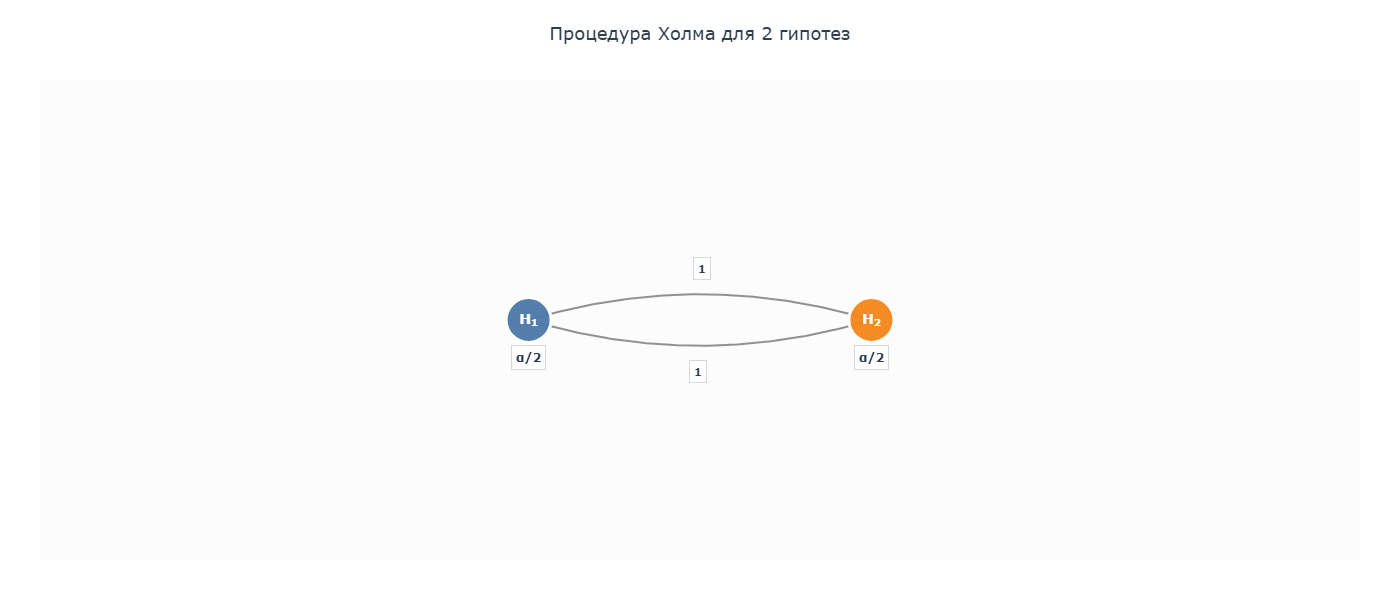

**Начальный вектор весов:** $\boldsymbol{\alpha} = (\alpha/2,\, \alpha/2)$ — бюджет разделён поровну.  
**Матрица переходов:**

$$
\mathbf{G} = \begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}.
$$


**Интерпретация:**

Если отвергнута $H_1$, её уровень $\alpha/2$ полностью переходит к $H_2$ (ребро с весом 1), так что теперь $H_2$ будет проверяться на уровне $\alpha/2 + \alpha/2 = \alpha$. Если же первой будет отвергнута $H_2$, её уровень аналогично передаётся $H_1$. Таким образом, граф из двух вершин с симметричными рёбрами полностью кодирует процедуру Холма для $m = 2$. Как мы увидим далее, обобщение на $m$ гипотез потребует полносвязного графа с равными весами $g_{ij} = 1/(m-1)$, и это будет в точности процедура Холма.

In [8]:
# Ячейка 1: Импорт библиотек и настройка
import numpy as np
import networkx as nx
import plotly.graph_objects as go
from fractions import Fraction

In [38]:
# Ячейка 2: Исправленная функция визуализации
def draw_graph(alpha_vec, G_matrix,
               title="Графическое представление гипотез",
               width=800, height=600,
               show_alpha_values=True,
               alpha_symbol="α"):
    """
    Строит интерактивный ориентированный граф гипотез.

    Параметры:
    - alpha_vec: вектор начальных весов α_i
    - G_matrix: матрица переходов g_{ij}
    - title: заголовок графика
    - width, height: размеры полотна в пикселях
    - show_alpha_values: показывать ли числовые значения α на вершинах
    - alpha_symbol: символ для обозначения α (по умолчанию "α")
    """
    m = len(alpha_vec)
    G = nx.DiGraph()

    # Добавляем вершины
    for i in range(m):
        G.add_node(i, weight=alpha_vec[i])

    # Добавляем рёбра
    for i in range(m):
        for j in range(m):
            if G_matrix[i, j] > 0 and i != j:
                G.add_edge(i, j, weight=G_matrix[i, j])

    # Функция для форматирования α весов в виде долей от α
    def format_alpha_fraction(value, total_alpha=0.05):
        """Форматирует вес вершины как долю от α"""
        if value == 0:
            return "0"

        # Вычисляем отношение к стандартному α
        ratio = value / total_alpha
        frac = Fraction(ratio).limit_denominator(100)

        if frac.numerator == 0:
            return "0"
        elif frac.numerator == frac.denominator:
            return f"{alpha_symbol}"
        elif frac.denominator == 1:
            return f"{frac.numerator}{alpha_symbol}"
        else:
            return f"{alpha_symbol}/{frac.denominator}"

    # Функция для форматирования весов рёбер
    def format_edge_weight(value):
        """Форматирует вес ребра как обыкновенную дробь"""
        if value == 0:
            return "0"
        if value == 1:
            return "1"
        if abs(value - 0.5) < 1e-10:
            return "1/2"
        if abs(value - 1/3) < 1e-10:
            return "1/3"
        if abs(value - 2/3) < 1e-10:
            return "2/3"
        if abs(value - 0.25) < 1e-10:
            return "1/4"
        if abs(value - 0.75) < 1e-10:
            return "3/4"

        frac = Fraction(value).limit_denominator(1000)
        return f"{frac.numerator}/{frac.denominator}"

    # Расположение вершин
    if m == 1:
        pos = {0: np.array([0, 0])}
    elif m == 2:
        pos = {0: np.array([-1, 0]), 1: np.array([1, 0])}
    elif m == 3:
        pos = {
            0: np.array([0, np.sqrt(3)/2]),
            1: np.array([-0.8, -np.sqrt(3)/4]),
            2: np.array([0.8, -np.sqrt(3)/4])
        }
    elif m == 4:
        pos = {
            0: np.array([-1, 1]),
            1: np.array([1, 1]),
            2: np.array([1, -1]),
            3: np.array([-1, -1])
        }
    elif m <= 6:
        pos = nx.shell_layout(G)
    else:
        pos = nx.kamada_kawai_layout(G)

    # Создаём фигуру Plotly
    fig = go.Figure()

    # Цветовая палитра для вершин
    vertex_colors = [
        '#4C78A8',  # синий
        '#F58518',  # оранжевый
        '#E45756',  # красный
        '#72B7B2',  # бирюзовый
        '#54A24B',  # зелёный
        '#EECA3B',  # жёлтый
        '#B279A2',  # фиолетовый
        '#FF9DA6',  # розовый
    ]

    # Множество для отслеживания уже нарисованных встречных рёбер
    drawn_reverse_edges = set()

    # Рисуем рёбра
    for u, v in G.edges():
        # Если это встречное ребро и мы его ещё не рисовали
        has_reverse = (v, u) in G.edges()

        # Пропускаем встречные рёбра, которые уже нарисованы как изогнутые
        if has_reverse and (v, u) in drawn_reverse_edges:
            continue

        # Координаты вершин
        x0, y0 = pos[u]
        x1, y1 = pos[v]

        # Вес ребра
        weight = G.edges[u, v]['weight']
        weight_str = format_edge_weight(weight)

        if has_reverse:
            # Рисуем оба встречных ребра с разными изгибами
            reverse_weight = G.edges[v, u]['weight']
            reverse_weight_str = format_edge_weight(reverse_weight)

            # Первое ребро: u -> v (изгиб в одну сторону)
            curvature1 = 0.3

            dx = x1 - x0
            dy = y1 - y0
            dist = np.sqrt(dx**2 + dy**2)
            if dist > 0:
                nx_vec = -dy / dist
                ny_vec = dx / dist
            else:
                nx_vec, ny_vec = 0, 0

            cx1 = (x0 + x1) / 2 + nx_vec * curvature1
            cy1 = (y0 + y1) / 2 + ny_vec * curvature1

            # Второе ребро: v -> u (изгиб в другую сторону)
            curvature2 = -0.3

            cx2 = (x0 + x1) / 2 + nx_vec * curvature2
            cy2 = (y0 + y1) / 2 + ny_vec * curvature2

            # Рисуем первое ребро (u -> v)
            t = np.linspace(0, 1, 100)
            bx1 = (1-t)**2 * x0 + 2*(1-t)*t * cx1 + t**2 * x1
            by1 = (1-t)**2 * y0 + 2*(1-t)*t * cy1 + t**2 * y1

            fig.add_trace(go.Scatter(
                x=bx1, y=by1,
                mode='lines',
                line=dict(color='rgba(100, 100, 100, 0.7)', width=2.0),
                hoverinfo='text',
                text=f"H{u+1} → H{v+1}<br>Вес: {weight_str}",
                showlegend=False
            ))

            # Стрелка для первого ребра
            fig.add_annotation(
                x=bx1[-1], y=by1[-1],
                ax=bx1[-2], ay=by1[-2],
                xref='x', yref='y',
                axref='x', ayref='y',
                showarrow=True,
                arrowhead=2,
                arrowsize=1.5,
                arrowwidth=2.0,
                arrowcolor='rgba(100, 100, 100, 0.7)'
            )

            # Подпись веса первого ребра (смещена в сторону изгиба)
            mid_idx1 = len(t) // 2
            fig.add_annotation(
                x=bx1[mid_idx1] + nx_vec * curvature1 * 0.5,
                y=by1[mid_idx1] + ny_vec * curvature1 * 0.5,
                text=f"<b>{weight_str}</b>",
                showarrow=False,
                font=dict(size=11, color='#2c3e50'),
                bgcolor='rgba(255, 255, 255, 0.9)',
                borderpad=4,
                borderwidth=1,
                bordercolor='rgba(128, 128, 128, 0.3)'
            )

            # Рисуем второе ребро (v -> u)
            bx2 = (1-t)**2 * x1 + 2*(1-t)*t * cx2 + t**2 * x0
            by2 = (1-t)**2 * y1 + 2*(1-t)*t * cy2 + t**2 * y0

            fig.add_trace(go.Scatter(
                x=bx2, y=by2,
                mode='lines',
                line=dict(color='rgba(100, 100, 100, 0.7)', width=2.0),
                hoverinfo='text',
                text=f"H{v+1} → H{u+1}<br>Вес: {reverse_weight_str}",
                showlegend=False
            ))

            # Стрелка для второго ребра
            fig.add_annotation(
                x=bx2[-1], y=by2[-1],
                ax=bx2[-2], ay=by2[-2],
                xref='x', yref='y',
                axref='x', ayref='y',
                showarrow=True,
                arrowhead=2,
                arrowsize=1.5,
                arrowwidth=2.0,
                arrowcolor='rgba(100, 100, 100, 0.7)'
            )

            # Подпись веса второго ребра (смещена в сторону изгиба)
            mid_idx2 = len(t) // 2
            fig.add_annotation(
                x=bx2[mid_idx2] + nx_vec * curvature2 * 0.5,
                y=by2[mid_idx2] + ny_vec * curvature2 * 0.5,
                text=f"<b>{reverse_weight_str}</b>",
                showarrow=False,
                font=dict(size=11, color='#2c3e50'),
                bgcolor='rgba(255, 255, 255, 0.9)',
                borderpad=4,
                borderwidth=1,
                bordercolor='rgba(128, 128, 128, 0.3)'
            )

            # Отмечаем, что эта пара встречных рёбер уже нарисована
            drawn_reverse_edges.add((u, v))

        else:
            # Простое прямое ребро
            fig.add_annotation(
                x=x1, y=y1,
                ax=x0, ay=y0,
                xref='x', yref='y',
                axref='x', ayref='y',
                showarrow=True,
                arrowhead=2,
                arrowsize=1.5,
                arrowwidth=2.0,
                arrowcolor='rgba(100, 100, 100, 0.7)',
                text="",
                hovertext=f"H{u+1} → H{v+1}<br>Вес: {weight_str}",
            )

            # Подпись веса ребра на середине
            mid_x = (x0 + x1) / 2
            mid_y = (y0 + y1) / 2

            # Смещение подписи для лучшей читаемости
            dx = x1 - x0
            dy = y1 - y0
            dist = np.sqrt(dx**2 + dy**2)
            if dist > 0:
                offset_x = -dy / dist * 0.15
                offset_y = dx / dist * 0.15
            else:
                offset_x, offset_y = 0, 0

            fig.add_annotation(
                x=mid_x + offset_x, y=mid_y + offset_y,
                text=f"<b>{weight_str}</b>",
                showarrow=False,
                font=dict(size=11, color='#2c3e50'),
                bgcolor='rgba(255, 255, 255, 0.9)',
                borderpad=4,
                borderwidth=1,
                bordercolor='rgba(128, 128, 128, 0.3)'
            )

    # Рисуем вершины
    for i in range(m):
        x, y = pos[i]
        weight = alpha_vec[i]
        weight_str = format_alpha_fraction(weight)
        color = vertex_colors[i % len(vertex_colors)]

        # Основная вершина
        fig.add_trace(go.Scatter(
            x=[x], y=[y],
            mode='markers+text',
            marker=dict(
                size=45,
                color=color,
                line=dict(color='white', width=3),
                opacity=0.95
            ),
            text=f"<b>H<sub>{i+1}</sub></b>",
            textposition='middle center',
            textfont=dict(size=14, color='white'),
            hovertext=f"Гипотеза H{i+1}<br>Уровень: {weight_str}",
            hoverinfo='text',
            showlegend=False
        ))

        # Подпись α под вершиной
        if show_alpha_values and weight > 0:
            fig.add_annotation(
                x=x, y=y - 0.22,
                text=f"<b>{weight_str}</b>",
                showarrow=False,
                font=dict(size=12, color='#2c3e50'),
                bgcolor='rgba(255, 255, 255, 0.85)',
                borderpad=4,
                borderwidth=1,
                bordercolor='rgba(128, 128, 128, 0.3)'
            )
        elif show_alpha_values:
            fig.add_annotation(
                x=x, y=y - 0.22,
                text="<b>0</b>",
                showarrow=False,
                font=dict(size=12, color='#95a5a6'),
                bgcolor='rgba(255, 255, 255, 0.85)',
                borderpad=4
            )

    # Настройка layout
    fig.update_layout(
        title=dict(
            text=title,
            font=dict(size=18, color='#2c3e50'),
            x=0.5,
            xanchor='center'
        ),
        width=width,
        height=height,
        showlegend=False,
        plot_bgcolor='rgba(252, 252, 252, 1)',
        paper_bgcolor='white',
        xaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False,
            scaleanchor='y',
            scaleratio=1
        ),
        yaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False
        ),
        margin=dict(t=80, b=40, l=40, r=40)
    )

    # Устанавливаем одинаковый масштаб по осям
    fig.update_xaxes(range=[-1.6, 1.6])
    fig.update_yaxes(range=[-1.4, 1.4])

    return fig

In [46]:
# Поправка Бонферрони
m = 3
alpha_vec = np.full(m, alpha/m)
G_matrix = np.zeros((m, m))

fig = draw_graph(alpha_vec=alpha_vec, G_matrix=G_matrix,
                title=f"Поправка Бонферрони для {m} гипотез",
                width=600, height=400,
                show_alpha_values=True)
fig.show()

In [40]:
# процедура Холма

m = 2
alpha_vec = np.full(m, alpha/m)
g_weight = 1.0 / (m - 1)
G_matrix = np.full((m, m), g_weight)
np.fill_diagonal(G_matrix, 0)

fig = draw_graph(alpha_vec=alpha_vec, G_matrix=G_matrix,
                title=f"Процедура Холма для {m} гипотез",
                width=1400, height=600,
                show_alpha_values=True)
fig.show()

### 2.2 Алгоритм последовательного тестирования
Детальное описание Алгоритма 1 из статьи [1] (инициализация, выбор гипотезы, проверка, обновление графа).  
Повторение шагов до остановки. Свойства: сильный контроль FWER, shortcut, независимость от порядка удаления.

In [ ]:
# TODO: Псевдокод / заготовка функции graphical_test

### 2.3 Связь с замкнутой процедурой тестирования
Определение замкнутой процедуры тестирования (closed testing procedure).  
Как графический алгоритм порождает веса для всех пересечений гипотез и удовлетворяет условию монотонности.  
Доказательство того, что графический подход – это shortcut замкнутого теста, гарантирующий контроль FWER (Appendix A в [1]).

## 3. Детальный разбор ключевых примеров

### 3.1 Пример 0: поправка Бонферрони как вырожденный граф
Граф без рёбер: начальные веса α/m, все g_ij = 0. Демонстрация того, что это приводит к обычной поправке Бонферрони.

In [ ]:
# TODO: Настройка графа Бонферрони, запуск теста, вывод результата

### 3.2 Пример 1: процедура Холма как граф
Построение полносвязного графа с равными весами переходов. Пошаговая анимация/вывод состояний для заданных p-значений (Рис. 4 из [1]).

In [ ]:
# TODO: Реализация процедуры Холма через графический алгоритм
# Визуализация начального, промежуточных и конечного графа

### 3.3 Пример 2: gatekeeping процедура для двух семейств
Первичные гипотезы с весами α/2, вторичные с нулевыми начальными весами. Показать оригинальную и улучшенную версию с ε-рёбрами (Рис. 12 из [1]).

In [ ]:
# TODO: Класс/функция, поддерживающая ε-веса; пример gatekeeping

### 3.4 Интерактивная визуализация и код
Объединение примеров в единый класс `Graph`. Возможность менять p-значения и топологию графа в виджетах (если позволяет время).  
Вывод текущих весов вершин и матрицы переходов после каждого шага.

In [ ]:
# TODO: Интерактивные элементы (ipywidgets) для демонстрации работы алгоритма в реальном времени

## 4. Расширения графического подхода для обобщённых ошибок

### 4.1 Контроль k-FWER и FDP
Мотивация использования k-FWER и FDP в разведочных A/B-тестах.  
Описание дополненной (augmented) и обобщённой (generalised) процедур (Статья [2], Алгоритмы 1, 3, 4, 6).  
Сравнение их мощности и ограничений на примере фармакодинамического исследования (раздел 6.1).

In [ ]:
# TODO: Реализация augmented_k_FWER и augmented_FDP, загрузка данных кейса из статьи [2]

### 4.2 Адаптация к динамическим A/B-тестам
Примеры многошаговых протоколов: Pre-RELAX-AHF (6-из-9 критерий) и ATMOSPHERE (иерархия из трёх первичных и двух вторичных семейств).  
Демонстрация построения графа и применения дополненных процедур для этих кейсов.

In [ ]:
# TODO: Настройка графа для ATMOSPHERE, вызов k-FWER/FDP процедуры

## 5. Программная реализация на Python

### 5.1 Инструменты и библиотеки
Обзор используемых Python-библиотек: `numpy`, `networkx`, `matplotlib`.  
Структура кода: класс `Graph` и функция `graphical_test`. Пример реализации Алгоритма 1 из [1].

In [ ]:
# TODO: Полный код базового графического теста (уже подготовлен, но показать ключевые моменты)

### 5.2 Реализация дополненных процедур для k-FWER и FDP на Python
Функции `augmented_k_FWER` и `augmented_FDP`. Демонстрация работы на данных из кейсов.  
Замечание о вычислительной сложности и упрощённых (streamlined) версиях.

In [ ]:
# TODO: Код функций augmented_k_FWER / augmented_FDP; сравнение результатов с обычным FWER

## 6. Сравнительный анализ и практические рекомендации

### 6.1 Когда выбирать графический подход
Критерии выбора: иерархическая структура гипотез, необходимость прозрачной коммуникации, потребность в «рециклинге» уровня значимости.  
Сравнение с методом Бенджамини–Хохберг и процедурами на основе ресемплинга.  
Ограничения, связанные с корреляцией p-значений.

### 6.2 «Подводные камни» и направления развития
Проблемы обобщённой процедуры (не передаёт уровень гипотезам с малым числом доноров), вычислительные трудности при больших m и k>1.  
Открытые вопросы: скорректированные p-значения для дополненных процедур, онлайн-мониторинг экспериментов.

## 7. Заключение и Q&A

Резюме основных идей. Домашнее задание: воспроизвести примеры и построить граф для гипотетического A/B-теста с тремя вариантами и двумя метриками.  
Ответы на вопросы.

In [ ]:
# Место для дополнительных интерактивных вопросов или демонстраций